In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/s1s2_landslide_reference_data.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset")

In [ ]:
import os

print(os.path.exists("/content/drive/MyDrive/s1s2_landslide_reference_data.zip"))

True


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/s1s2_landslide_reference_data.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    print(z.namelist()[:50])   # first 50 files/folders

['s1s2_landslide_reference_data/', 's1s2_landslide_reference_data/original_scenes/', 's1s2_landslide_reference_data/original_scenes/BR0001/', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__DEM.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__SLOPE.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__files_meta.csv', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__None__None__MASK.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29_2019-01-10__DES_COHVV.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ALPHA.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ANISOTROPY.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ENTROPY.tif', 's1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_gVH.tif', 's1s2_landslide_referen

In [ ]:
!pip install h5py geopandas rasterio shapely pycocotools

In [ ]:
import h5py

train_file = "/content/dataset/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

with h5py.File(train_file,'r') as f:
    print("Keys:", list(f.keys()))

    for key in f.keys():
        print("\n", key)
        print("Shape:", f[key].shape)
        print("Datatype:", f[key].dtype)


Keys: ['None_DEM', 'None_MASK', 'None_SLOPE', 'POST1_ALPHA', 'POST1_ANISOTROPY', 'POST1_B02', 'POST1_B03', 'POST1_B04', 'POST1_B05', 'POST1_B06', 'POST1_B07', 'POST1_B08', 'POST1_B11', 'POST1_B12', 'POST1_B8A', 'POST1_COHVV', 'POST1_ENTROPY', 'POST1_NDVI', 'POST1_gVH', 'POST1_gVV', 'POST2_ALPHA', 'POST2_ANISOTROPY', 'POST2_COHVV', 'POST2_ENTROPY', 'POST2_gVH', 'POST2_gVV', 'POST3_ALPHA', 'POST3_ANISOTROPY', 'POST3_COHVV', 'POST3_ENTROPY', 'POST3_gVH', 'POST3_gVV', 'PRE1_ALPHA', 'PRE1_ANISOTROPY', 'PRE1_B02', 'PRE1_B03', 'PRE1_B04', 'PRE1_B05', 'PRE1_B06', 'PRE1_B07', 'PRE1_B08', 'PRE1_B11', 'PRE1_B12', 'PRE1_B8A', 'PRE1_COHVV', 'PRE1_ENTROPY', 'PRE1_NDVI', 'PRE1_gVH', 'PRE1_gVV', 'PRE2_ALPHA', 'PRE2_ANISOTROPY', 'PRE2_COHVV', 'PRE2_ENTROPY', 'PRE2_gVH', 'PRE2_gVV', 'PRE3_ALPHA', 'PRE3_ANISOTROPY', 'PRE3_ENTROPY', 'PRE3_gVH', 'PRE3_gVV']

 None_DEM
Shape: (355, 1, 128, 128)
Datatype: float32

 None_MASK
Shape: (355, 1, 128, 128)
Datatype: float32

 None_SLOPE
Shape: (355, 1, 128, 128)
D

In [ ]:
train_path = "/content/dataset/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

val_path = "/content/dataset/s1s2_landslide_reference_data/reference_data/val_n3_s1s2.h5"

test_path = "/content/dataset/s1s2_landslide_reference_data/reference_data/testspt_n3_s1s2.h5"

In [ ]:
train_ds = LandslideDataset(train_path)

val_ds = LandslideDataset(val_path)

test_ds = LandslideDataset(test_path)

NameError: name 'LandslideDataset' is not defined

In [ ]:
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Train: 355
Validation: 88
Test: 76


In [ ]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_ds,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_ds,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
images, targets = next(iter(train_loader))

print(images[0].shape)
print(targets[0]["masks"].shape)
print(targets[0]["boxes"])

torch.Size([59, 128, 128])
torch.Size([1, 128, 128])
tensor([[53.,  0., 72.,  9.]])


In [ ]:
import h5py
import numpy as np

with h5py.File(train_path, 'r') as f:
    masks = f['None_MASK'][:]

empty = np.sum(
    masks.reshape(masks.shape[0], -1).sum(axis=1) == 0
)

print("Empty masks:", empty)

Empty masks: 0


In [ ]:
print("Number of channels:", len(FEATURE_KEYS))

Number of channels: 59


In [ ]:
images, targets = next(iter(train_loader))

print(type(images[0]))
print(images[0].shape)
print(images[0].dtype)

print(targets[0].keys())
print(targets[0]["boxes"].shape)
print(targets[0]["masks"].shape)

<class 'torch.Tensor'>
torch.Size([59, 128, 128])
torch.float32
dict_keys(['boxes', 'labels', 'masks'])
torch.Size([1, 4])
torch.Size([1, 128, 128])


In [ ]:
import torch.nn as nn

from torchvision.models.detection import MaskRCNN
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone

backbone = resnet_fpn_backbone(
    backbone_name="resnet50",
    weights=None
)

backbone.body.conv1 = nn.Conv2d(
    59,
    64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

model = MaskRCNN(
    backbone=backbone,
    num_classes=2,
    image_mean=[0.0] * 59,
    image_std=[1.0] * 59
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(59, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool

In [ ]:
images, targets = next(iter(train_loader))

images = [img.to(device) for img in images]

targets = [
    {k:v.to(device) for k,v in t.items()}
    for t in targets
]

model.train()

loss_dict = model(images, targets)

print(loss_dict)

{'loss_classifier': tensor(0., device='cuda:0', grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(25147.3906, device='cuda:0', grad_fn=<DivBackward0>), 'loss_mask': tensor(79832.9766, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_objectness': tensor(660.8967, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(118.7776, device='cuda:0', grad_fn=<DivBackward0>)}


In [ ]:
import torch

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [ ]:
model.train()

running_loss = 0

for images, targets in train_loader:

    images = [img.to(device) for img in images]

    targets = [
        {k:v.to(device) for k,v in t.items()}
        for t in targets
    ]

    loss_dict = model(images, targets)

    losses = sum(loss for loss in loss_dict.values())

    optimizer.zero_grad()

    losses.backward()

    optimizer.step()

    running_loss += losses.item()

print("Training Loss:", running_loss/len(train_loader))

Training Loss: 5074.33533497071


In [ ]:
num_epochs = 10

train_losses = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for images, targets in train_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)

        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()

        losses.backward()

        optimizer.step()

        running_loss += losses.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_loss:.4f}"
    )

Epoch [1/10] Train Loss: 30.2199
Epoch [2/10] Train Loss: 17.3179
Epoch [3/10] Train Loss: 10.7908
Epoch [4/10] Train Loss: 8.3014
Epoch [5/10] Train Loss: 6.3948
Epoch [6/10] Train Loss: 5.2528
Epoch [7/10] Train Loss: 4.5983
Epoch [8/10] Train Loss: 4.0339
Epoch [9/10] Train Loss: 3.4625
Epoch [10/10] Train Loss: 3.0790


In [ ]:
model.train()

val_loss = 0

with torch.no_grad():

    for images, targets in val_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k:v.to(device) for k,v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)

        loss = sum(v for v in loss_dict.values())

        val_loss += loss.item()

val_loss /= len(val_loader)

print("Validation Loss:", val_loss)

Validation Loss: 3.624722811308774


In [ ]:
model.eval()

images, targets = next(iter(test_loader))

image = images[0].to(device)

with torch.no_grad():
    prediction = model([image])

print(prediction[0].keys())

dict_keys(['boxes', 'labels', 'scores', 'masks'])


In [ ]:
print(prediction[0]["scores"][:10])

tensor([0.4735, 0.3931, 0.3639, 0.3125, 0.2938, 0.2876, 0.2460, 0.2411, 0.2284,
        0.2284], device='cuda:0')


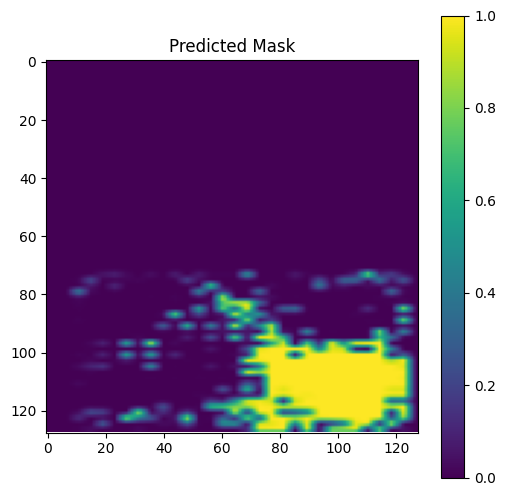

In [ ]:
import matplotlib.pyplot as plt

pred_mask = prediction[0]["masks"][0,0].cpu().numpy()

plt.figure(figsize=(6,6))
plt.imshow(pred_mask)
plt.colorbar()
plt.title("Predicted Mask")
plt.show()

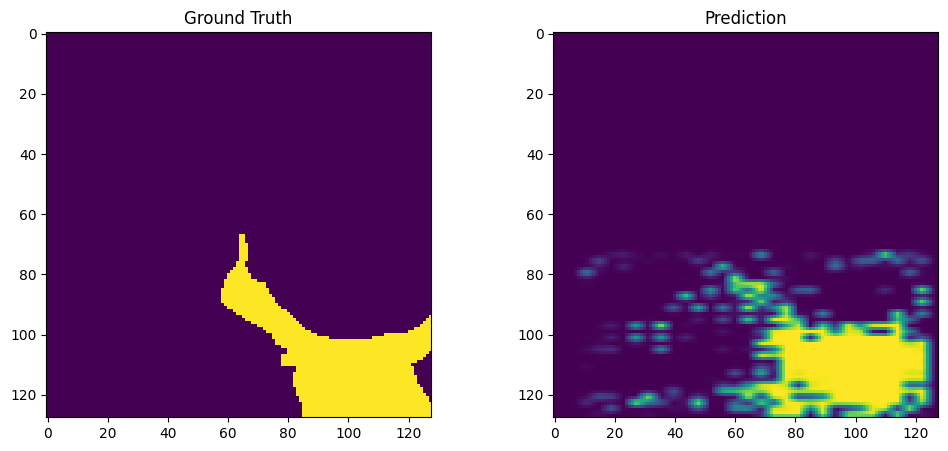

In [ ]:
gt_mask = targets[0]["masks"][0].cpu().numpy()

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(gt_mask)
plt.title("Ground Truth")

plt.subplot(1,2,2)
plt.imshow(pred_mask)
plt.title("Prediction")

plt.show()

In [ ]:
import numpy as np

pred_binary = (pred_mask > 0.5).astype(np.uint8)

intersection = np.logical_and(
    pred_binary,
    gt_mask
).sum()

union = np.logical_or(
    pred_binary,
    gt_mask
).sum()

iou = intersection / (union + 1e-6)

print("IoU =", iou)

IoU = 0.5693045560818684


In [ ]:
dice = (
    2 * intersection
) / (
    pred_binary.sum()
    + gt_mask.sum()
    + 1e-6
)

print("Dice =", dice)

Dice = 0.7255501220276437


In [ ]:
import numpy as np

model.eval()

ious = []
dices = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            if len(pred["masks"]) == 0:
                continue

            pred_mask = pred["masks"][0,0].cpu().numpy()
            pred_mask = (pred_mask > 0.5).astype(np.uint8)

            gt_mask = target["masks"][0].cpu().numpy()

            intersection = np.logical_and(
                pred_mask,
                gt_mask
            ).sum()

            union = np.logical_or(
                pred_mask,
                gt_mask
            ).sum()

            iou = intersection / (union + 1e-6)

            dice = (
                2 * intersection
            ) / (
                pred_mask.sum()
                + gt_mask.sum()
                + 1e-6
            )

            ious.append(iou)
            dices.append(dice)

print("Mean IoU :", np.mean(ious))
print("Mean Dice:", np.mean(dices))

Mean IoU : 0.13782378256929198
Mean Dice: 0.21007496361626427


In [ ]:
import numpy as np
import torch

model.eval()

ious = []
dices = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            gt_mask = target["masks"][0].cpu().numpy().astype(np.uint8)

            pred_masks = pred["masks"].cpu().numpy()
            scores = pred["scores"].cpu().numpy()

            combined_mask = np.zeros_like(gt_mask)

            for mask, score in zip(pred_masks, scores):

                if score > 0.5:
                    combined_mask = np.logical_or(
                        combined_mask,
                        mask[0] > 0.5
                    )

            combined_mask = combined_mask.astype(np.uint8)

            intersection = np.logical_and(
                combined_mask,
                gt_mask
            ).sum()

            union = np.logical_or(
                combined_mask,
                gt_mask
            ).sum()

            if union == 0:
                continue

            iou = intersection / union

            dice = (
                2 * intersection
            ) / (
                combined_mask.sum()
                + gt_mask.sum()
                + 1e-6
            )

            ious.append(iou)
            dices.append(dice)

print("Mean IoU :", np.mean(ious))
print("Mean Dice:", np.mean(dices))

Mean IoU : 0.10435324121020996
Mean Dice: 0.14945017535360283


In [ ]:
images, targets = next(iter(test_loader))

image = images[0].to(device)

model.eval()

with torch.no_grad():
    pred = model([image])

print(pred[0]["scores"][:20])

tensor([0.4735, 0.3931, 0.3639, 0.3125, 0.2938, 0.2876, 0.2460, 0.2411, 0.2284,
        0.2284, 0.2164, 0.2164, 0.2036, 0.2030, 0.1940, 0.1908, 0.1887, 0.1877,
        0.1788, 0.1788], device='cuda:0')


In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-5
)

In [ ]:
additional_epochs = 10

for epoch in range(additional_epochs):

    # TRAIN
    model.train()

    train_loss = 0

    for images, targets in train_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k:v.to(device) for k,v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)

        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        train_loss += losses.item()

    train_loss /= len(train_loader)

    # VALIDATION
    model.train()

    val_loss = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images = [img.to(device) for img in images]

            targets = [
                {k:v.to(device) for k,v in t.items()}
                for t in targets
            ]

            loss_dict = model(images, targets)

            losses = sum(loss for loss in loss_dict.values())

            val_loss += losses.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch+11} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 11 | Train Loss: 2.0353 | Val Loss: 1.7217
Epoch 12 | Train Loss: 1.4164 | Val Loss: 1.3898
Epoch 13 | Train Loss: 1.1595 | Val Loss: 1.1443
Epoch 14 | Train Loss: 1.0218 | Val Loss: 1.0104
Epoch 15 | Train Loss: 0.8933 | Val Loss: 0.9461
Epoch 16 | Train Loss: 0.8562 | Val Loss: 0.8751
Epoch 17 | Train Loss: 0.7771 | Val Loss: 0.8461
Epoch 18 | Train Loss: 0.7224 | Val Loss: 0.7941
Epoch 19 | Train Loss: 0.6931 | Val Loss: 0.7768
Epoch 20 | Train Loss: 0.6788 | Val Loss: 0.7803


In [ ]:
import numpy as np
import torch

model.eval()

ious = []
dices = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            if len(pred["masks"]) == 0:
                continue

            gt_mask = target["masks"][0].cpu().numpy().astype(np.uint8)

            pred_masks = pred["masks"].cpu().numpy()
            scores = pred["scores"].cpu().numpy()

            combined_mask = np.zeros_like(gt_mask)

            for mask, score in zip(pred_masks, scores):

                if score > 0.3:      # lower threshold
                    combined_mask = np.logical_or(
                        combined_mask,
                        mask[0] > 0.5
                    )

            combined_mask = combined_mask.astype(np.uint8)

            intersection = np.logical_and(
                combined_mask,
                gt_mask
            ).sum()

            union = np.logical_or(
                combined_mask,
                gt_mask
            ).sum()

            if union == 0:
                continue

            iou = intersection / union

            dice = (
                2 * intersection
            ) / (
                combined_mask.sum()
                + gt_mask.sum()
                + 1e-6
            )

            ious.append(iou)
            dices.append(dice)

print("Mean IoU :", np.mean(ious))
print("Mean Dice:", np.mean(dices))

KeyboardInterrupt: 

In [ ]:
images, targets = next(iter(test_loader))

with torch.no_grad():
    pred = model([images[0].to(device)])

print(pred[0]["scores"][:20])

tensor([0.3370, 0.3247, 0.2810, 0.2749, 0.2506, 0.2188, 0.2164, 0.2146, 0.2021,
        0.2005, 0.1917, 0.1826, 0.1536, 0.1513, 0.1434, 0.1428, 0.1164, 0.1102,
        0.1054, 0.1053], device='cuda:0')


In [ ]:
torch.save(
    model.state_dict(),
    "/content/maskrcnn_epoch20.pth"
)

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-6
)

In [ ]:
best_val_loss = 0.7803   # Best validation loss so far (Epoch 19)

for epoch in range(21, 31):

    # ==========================
    # TRAINING
    # ==========================
    model.train()

    train_loss = 0.0

    for images, targets in train_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)

        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        train_loss += losses.item()

    train_loss /= len(train_loader)

    # ==========================
    # VALIDATION
    # ==========================
    model.train()

    val_loss = 0.0

    with torch.no_grad():

        for images, targets in val_loader:

            images = [img.to(device) for img in images]

            targets = [
                {k: v.to(device) for k, v in t.items()}
                for t in targets
            ]

            loss_dict = model(images, targets)

            losses = sum(loss for loss in loss_dict.values())

            val_loss += losses.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Save checkpoint every epoch
    torch.save(
        model.state_dict(),
        f"/content/maskrcnn_epoch_{epoch}.pth"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "/content/best_maskrcnn.pth"
        )

        print(
            f"✅ New best model saved! "
            f"Val Loss = {val_loss:.4f}"
        )

Epoch 21 | Train Loss: 0.6376 | Val Loss: 0.7268
✅ New best model saved! Val Loss = 0.7268
Epoch 22 | Train Loss: 0.5980 | Val Loss: 0.7035
✅ New best model saved! Val Loss = 0.7035
Epoch 23 | Train Loss: 0.5609 | Val Loss: 0.6699
✅ New best model saved! Val Loss = 0.6699
Epoch 24 | Train Loss: 0.5479 | Val Loss: 0.6805
Epoch 25 | Train Loss: 0.5250 | Val Loss: 0.6671
✅ New best model saved! Val Loss = 0.6671
Epoch 26 | Train Loss: 0.5126 | Val Loss: 0.6381
✅ New best model saved! Val Loss = 0.6381
Epoch 27 | Train Loss: 0.4971 | Val Loss: 0.6700
Epoch 28 | Train Loss: 0.4768 | Val Loss: 0.6592
Epoch 29 | Train Loss: 0.4698 | Val Loss: 0.6315
✅ New best model saved! Val Loss = 0.6315
Epoch 30 | Train Loss: 0.4469 | Val Loss: 0.6420


In [ ]:
# Load best model before testing
model.load_state_dict(
    torch.load("/content/best_maskrcnn.pth")
)

model.to(device)

MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(59, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool

In [ ]:
import numpy as np
import torch

model.eval()

ious = []
dices = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            if len(pred["masks"]) == 0:
                continue

            gt_mask = target["masks"][0].cpu().numpy().astype(np.uint8)

            pred_masks = pred["masks"].cpu().numpy()
            scores = pred["scores"].cpu().numpy()

            combined_mask = np.zeros_like(gt_mask)

            for mask, score in zip(pred_masks, scores):

                if score > 0.3:      # lower threshold
                    combined_mask = np.logical_or(
                        combined_mask,
                        mask[0] > 0.5
                    )

            combined_mask = combined_mask.astype(np.uint8)

            intersection = np.logical_and(
                combined_mask,
                gt_mask
            ).sum()

            union = np.logical_or(
                combined_mask,
                gt_mask
            ).sum()

            if union == 0:
                continue

            iou = intersection / union

            dice = (
                2 * intersection
            ) / (
                combined_mask.sum()
                + gt_mask.sum()
                + 1e-6
            )

            ious.append(iou)
            dices.append(dice)

print("Mean IoU :", np.mean(ious))
print("Mean Dice:", np.mean(dices))

Mean IoU : 0.32350441819256226
Mean Dice: 0.4376452922825969


In [ ]:
torch.save(
    model.state_dict(),
    "/content/best_maskrcnn_epoch29.pth"
)

In [ ]:
from google.colab import files

files.download("/content/best_maskrcnn_epoch29.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

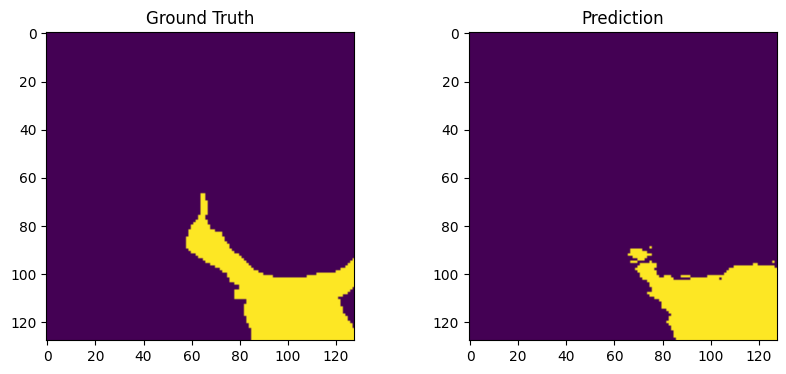

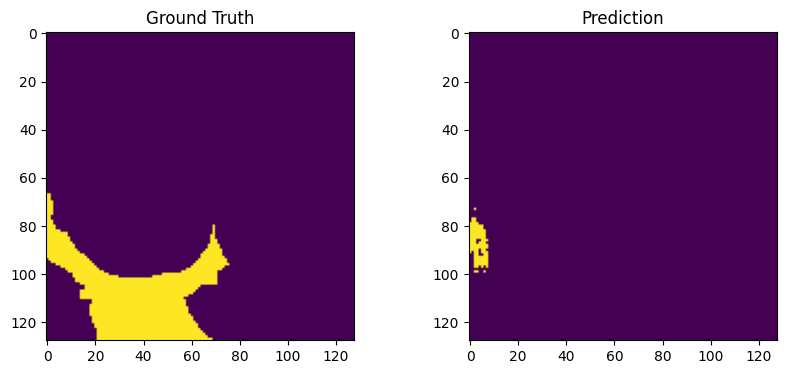

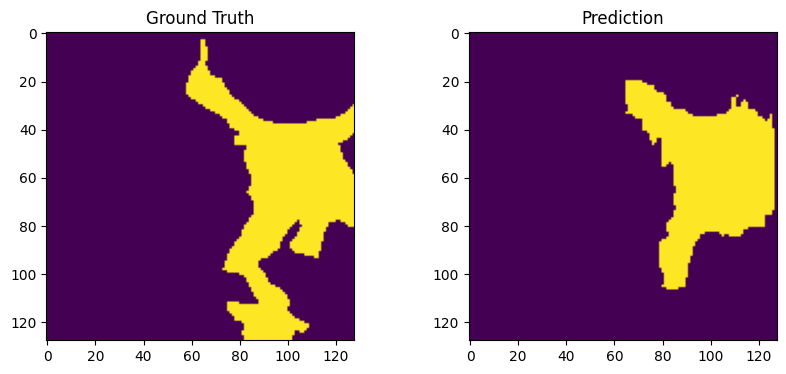

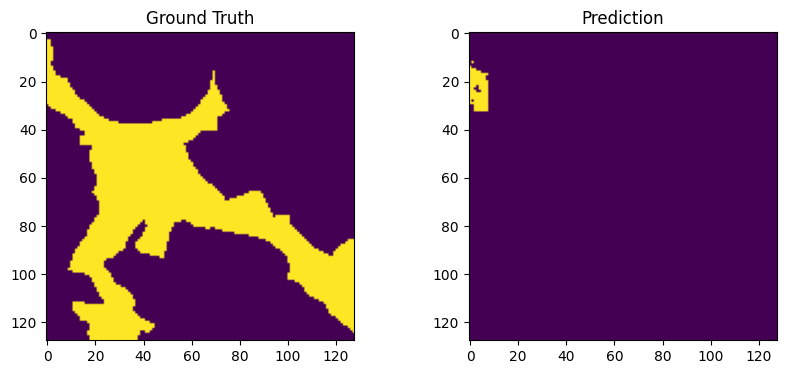

In [ ]:
import matplotlib.pyplot as plt

model.eval()

images, targets = next(iter(test_loader))

with torch.no_grad():
    preds = model([img.to(device) for img in images])

for i in range(4):

    gt = targets[i]["masks"][0].cpu().numpy()

    if len(preds[i]["masks"]) > 0:
        pred = preds[i]["masks"][0,0].cpu().numpy()
        pred = (pred > 0.5).astype(int)
    else:
        pred = gt * 0

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(gt)
    plt.title("Ground Truth")

    plt.subplot(1,2,2)
    plt.imshow(pred)
    plt.title("Prediction")

    plt.show()

In [ ]:
train_losses_1_20 = [
30.2199,
17.3179,
10.7908,
8.3014,
6.3948,
5.2528,
4.5983,
4.0339,
3.4625,
3.0790,
2.0353,
1.4164,
1.1595,
1.0218,
0.8933,
0.8562,
0.7771,
0.7224,
0.6931,
0.6788
]
train_losses_21_30 = [
0.6376,
0.5980,
0.5609,
0.5479,
0.5250,
0.5126,
0.4971,
0.4768,
0.4698,
0.4469
]
train_losses = train_losses_1_20 + train_losses_21_30
val_losses = [
1.7217,
1.3898,
1.1443,
1.0104,
0.9461,
0.8751,
0.8461,
0.7941,
0.7768,
0.7803,
0.7268,
0.7035,
0.6699,
0.6805,
0.6671,
0.6381,
0.6700,
0.6592,
0.6315,
0.6420
]


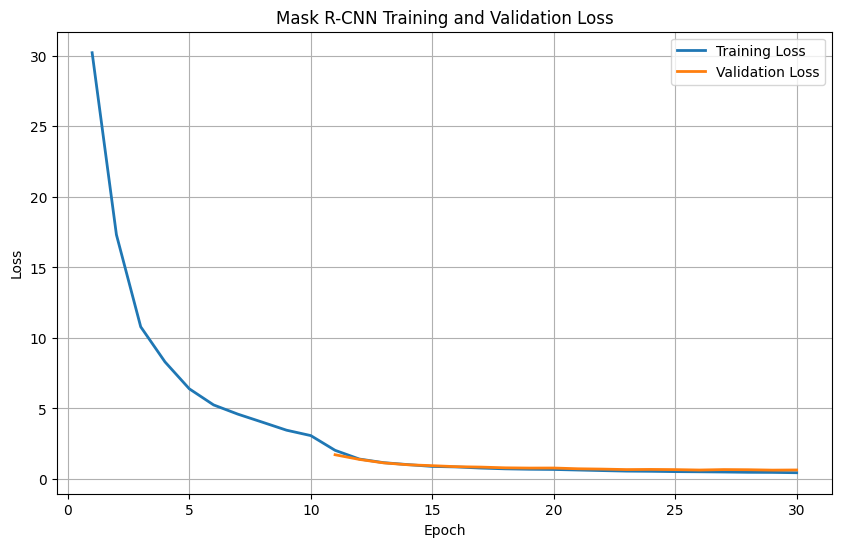

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    range(1,31),
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    range(11,31),
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mask R-CNN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

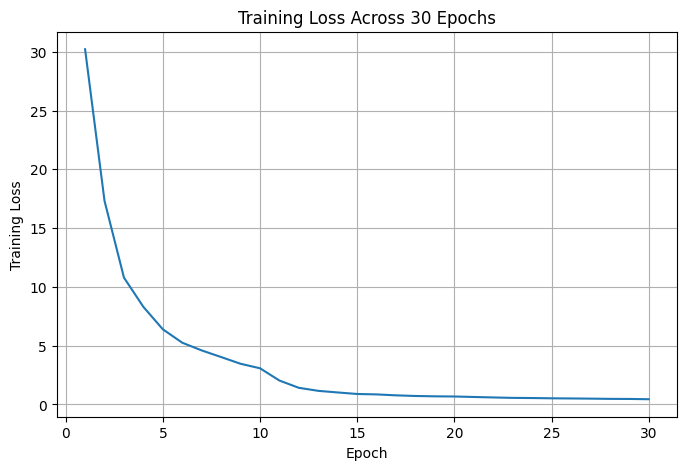

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(range(1,31), train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Across 30 Epochs")
plt.grid(True)

plt.show()

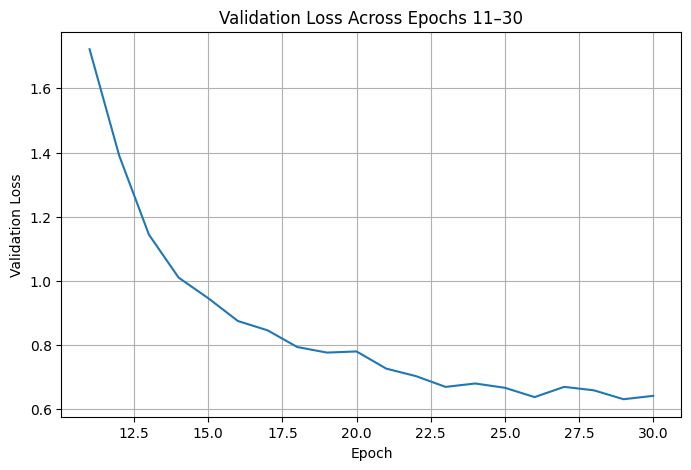

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(range(11,31), val_losses)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Across Epochs 11–30")
plt.grid(True)

plt.show()

In [ ]:
!pip install scikit-learn

In [ ]:
import numpy as np
import torch

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

model.eval()

all_gt = []
all_pred = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            gt_mask = target["masks"][0].cpu().numpy().astype(np.uint8)

            pred_mask = np.zeros_like(gt_mask)

            if len(pred["masks"]) > 0:

                scores = pred["scores"].cpu().numpy()
                masks = pred["masks"].cpu().numpy()

                for score, mask in zip(scores, masks):

                    if score > 0.3:
                        pred_mask = np.logical_or(
                            pred_mask,
                            mask[0] > 0.5
                        )

            pred_mask = pred_mask.astype(np.uint8)

            all_gt.extend(gt_mask.flatten())
            all_pred.extend(pred_mask.flatten())

precision = precision_score(
    all_gt,
    all_pred,
    zero_division=0
)

recall = recall_score(
    all_gt,
    all_pred,
    zero_division=0
)

f1 = f1_score(
    all_gt,
    all_pred,
    zero_division=0
)

accuracy = accuracy_score(
    all_gt,
    all_pred
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8818
Precision: 0.4870
Recall   : 0.6979
F1 Score : 0.5737


In [ ]:
import numpy as np
import torch
from sklearn.metrics import confusion_matrix

model.eval()

all_gt = []
all_pred = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        predictions = model(images)

        for pred, target in zip(predictions, targets):

            gt_mask = target["masks"][0].cpu().numpy().astype(np.uint8)

            pred_mask = np.zeros_like(gt_mask)

            if len(pred["masks"]) > 0:

                scores = pred["scores"].cpu().numpy()
                masks = pred["masks"].cpu().numpy()

                for score, mask in zip(scores, masks):

                    if score > 0.3:
                        pred_mask = np.logical_or(
                            pred_mask,
                            mask[0] > 0.5
                        )

            pred_mask = pred_mask.astype(np.uint8)

            all_gt.extend(gt_mask.flatten())
            all_pred.extend(pred_mask.flatten())

cm = confusion_matrix(all_gt, all_pred)

print(cm)

[[999018 104299]
 [ 42862  99005]]


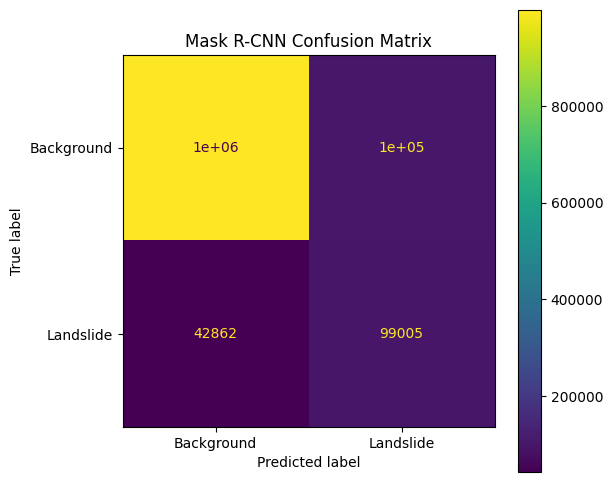

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Landslide"]
)

fig, ax = plt.subplots(figsize=(6,6))

disp.plot(ax=ax)

plt.title("Mask R-CNN Confusion Matrix")

plt.show()

In [ ]:
TN, FP, FN, TP = cm.ravel()

print(f"True Negatives : {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Positives : {TP}")

True Negatives : 999018
False Positives: 104299
False Negatives: 42862
True Positives : 99005


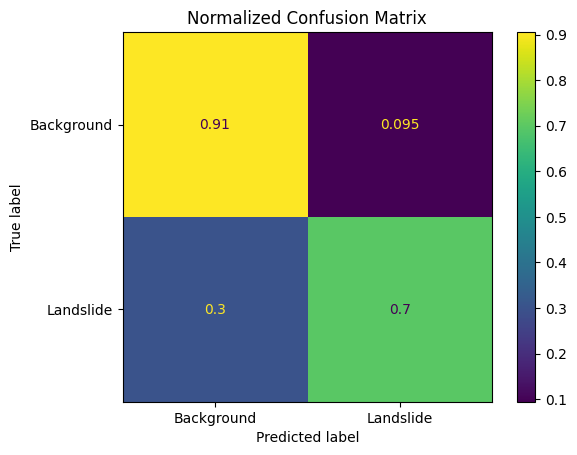

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(
    all_gt,
    all_pred,
    normalize='true',
    display_labels=["Background", "Landslide"]
)

plt.title("Normalized Confusion Matrix")
plt.show()

In [ ]:
import time
import numpy as np

model.eval()

times = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        start = time.time()

        _ = model(images)

        end = time.time()

        batch_time = end - start

        times.append(
            batch_time / len(images)
        )

print(
    f"Average Inference Time: {np.mean(times)*1000:.2f} ms/image"
)

print(
    f"FPS: {1/np.mean(times):.2f}"
)

Average Inference Time: 181.85 ms/image
FPS: 5.50


In [ ]:
import time

model.eval()

image = next(iter(test_loader))[0][0].to(device)

# Warm-up
with torch.no_grad():
    _ = model([image])

start = time.time()

with torch.no_grad():
    _ = model([image])

end = time.time()

print(
    f"Single Image Inference Time: {(end-start)*1000:.2f} ms"
)

Single Image Inference Time: 142.69 ms


In [ ]:
import time

epoch_times = []

for epoch in range(1):

    start_epoch = time.time()

    # training loop

    end_epoch = time.time()

    epoch_time = end_epoch - start_epoch

    epoch_times.append(epoch_time)

    print(
        f"Epoch Time: {epoch_time/60:.2f} minutes"
    )

Epoch Time: 0.00 minutes


In [ ]:
import time

model.train()

start = time.time()

for images, targets in train_loader:

    images = [img.to(device) for img in images]

    targets = [
        {k:v.to(device) for k,v in t.items()}
        for t in targets
    ]

    loss_dict = model(images, targets)

    losses = sum(loss for loss in loss_dict.values())

    optimizer.zero_grad()
    losses.backward()
    optimizer.step()

end = time.time()

epoch_time = end - start

print(
    f"One Epoch Time: {epoch_time/60:.2f} minutes"
)

print(
    f"Estimated 30-Epoch Training Time: {(epoch_time*30)/60:.2f} minutes"
)

One Epoch Time: 1.65 minutes
Estimated 30-Epoch Training Time: 49.54 minutes


In [ ]:
import torch

print(torch.cuda.get_device_name(0))

Tesla T4


In [ ]:
from google.colab import files

files.download("/content/best_maskrcnn_epoch29.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
torch.save({
    "epoch": 29,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict()
}, "/content/full_checkpoint_epoch29.pth")

In [ ]:
!pip install -q wandb

In [ ]:
pip install wandb weave

INFO: pip is looking at multiple versions of opentelemetry-sdk to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.9/214.9 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 82.7 

In [ ]:
import os
os.environ['WANDB_API_KEY'] = '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'

In [ ]:
wandb.init(
    project="Landslide-MaskRCNN",
    name="MaskRCNN_Epoch31_50",

    config={
        "model": "Mask R-CNN",
        "backbone": "ResNet50-FPN",
        "input_channels": 59,
        "batch_size": 4,
        "learning_rate": 1e-6,
        "epochs": 50,
        "resume_from_epoch": 30,
        "dataset": "S1S2 Landslide Dataset"
    }
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: kashishaggcha (kashishaggcha-thapar-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
print("Run Name:", wandb.run.name)
print("Run ID:", wandb.run.id)

Run Name: MaskRCNN_Epoch31_50
Run ID: lozq9kej


In [ ]:
import torch

In [ ]:
import torch
import torchvision
import torch.optim as optim
import numpy as np
import cv2
import os